# Tutorial 11 (T11): Building Programs to Implement K-Means Clustering

## 📌 Objective
Implement the **K-Means Clustering** algorithm on the agricultural crop recommendation dataset. Determine the optimal number of clusters $k$ using the **Elbow Method (Inertia / WCSS)**, train the K-Means model, extract the cluster centroids, and project cluster assignments in PCA space.

## 🔬 Key Concepts & Mathematical Formulas
- **K-Means Objective (Within-Cluster Sum of Squares / Inertia)**:
  $$J = \sum_{j=1}^k \sum_{x_i \in S_j} ||x_i - \mu_j||^2$$
- **Lloyd's Algorithm Steps**:
  1. **Initialization**: Select $k$ initial centroids $\mu_1, \dots, \mu_k$.
  2. **Assignment Step**: Assign each sample $x_i$ to its nearest centroid: $c^{(i)} = \arg\min_j ||x_i - \mu_j||^2$.
  3. **Update Step**: Recompute centroids: $\mu_j = \frac{1}{|S_j|} \sum_{x_i \in S_j} x_i$.
  4. Repeat until centroids stabilize (convergence).
- **K-Means++**: Intelligent probabilistic centroid initialization to avoid suboptimal local minima: chooses next center with probability $P(x) = \frac{D(x)^2}{\sum D(x')^2}$.

### Step 1: Import Required Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid", palette="muted")
print('K-Means libraries loaded!')

K-Means libraries loaded!


### Step 2: Load Data and Apply Standard Scaling

In [2]:
df = pd.read_csv('data/Crop_recommendation.csv')
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
X = df[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(f'Dataset loaded: {X.shape[0]} samples, {X.shape[1]} features.')
print('Features standardized to mean=0, std=1.')

Dataset loaded: 2200 samples, 7 features.
Features standardized to mean=0, std=1.


### Step 3: Determine Optimal $k$ via the Elbow Method
We iterate $k$ from 1 to 10 and compute the Within-Cluster Sum of Squares (Inertia). The 'elbow' point where the rate of inertia drop levels off indicates the optimal cluster count.

k =  1 -> Inertia:   15400.00
k =  2 -> Inertia:   11738.01
k =  3 -> Inertia:    9489.46
k =  4 -> Inertia:    8105.86
k =  5 -> Inertia:    6856.21
k =  6 -> Inertia:    6045.33
k =  7 -> Inertia:    5248.63
k =  8 -> Inertia:    4842.08
k =  9 -> Inertia:    4472.48
k = 10 -> Inertia:    4110.15


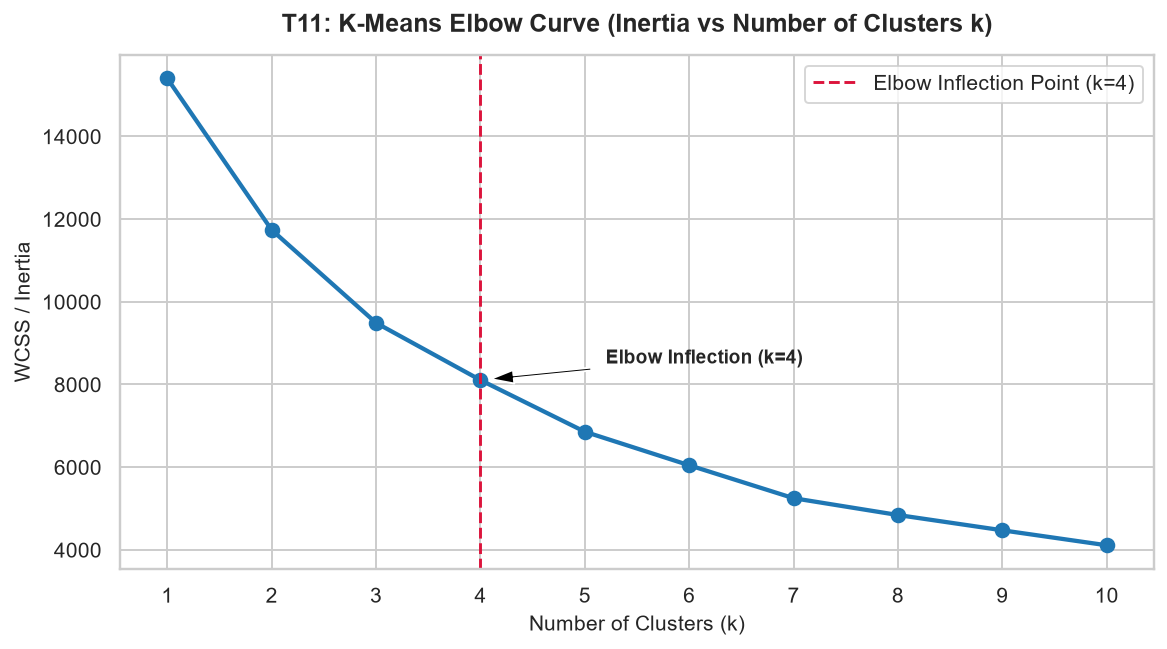

In [3]:
k_range = range(1, 11)
inertias = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8.5, 4.8), dpi=140)
plt.plot(list(k_range), inertias, marker='o', color='#1f77b4', linewidth=2.2, markersize=7)
plt.title('T11: K-Means Elbow Curve (Inertia vs Number of Clusters k)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Number of Clusters (k)', fontsize=11)
plt.ylabel('WCSS / Inertia', fontsize=11)
plt.xticks(list(k_range))
plt.axvline(x=4, color='crimson', linestyle='--', linewidth=1.5, label='Elbow Inflection Point (k=4)')
plt.annotate('Elbow Inflection (k=4)', xy=(4, inertias[3]), xytext=(5.2, inertias[3] + 400),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=7),
             fontweight='bold', fontsize=10)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

for k, val in zip(k_range, inertias):
    print(f'k = {k:2d} -> Inertia: {val:10.2f}')

### Step 4: Train Final K-Means Model ($k=4$)
We fit K-Means with $k=4$, `init='k-means++'`, and 10 random restarts to guarantee global convergence.

In [4]:
k_optimal = 4
kmeans = KMeans(n_clusters=k_optimal, init='k-means++', n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

sil = silhouette_score(X_scaled, kmeans_labels)
print(f'K-Means Convergence Achieved in {kmeans.n_iter_} iterations.')
print(f'Final Model Inertia: {kmeans.inertia_:.2f}')
print(f'Silhouette Score: {sil:.4f}')

counts = pd.Series(kmeans_labels).value_counts().sort_index()
for c, cnt in counts.items():
    print(f'  - Cluster {c+1}: {cnt} crops ({cnt/len(df):.1%})')

K-Means Convergence Achieved in 14 iterations.
Final Model Inertia: 8105.86
Silhouette Score: 0.2553
  - Cluster 1: 797 crops (36.2%)
  - Cluster 2: 618 crops (28.1%)
  - Cluster 3: 585 crops (26.6%)
  - Cluster 4: 200 crops (9.1%)


### Step 5: Cluster Centroids in Original Agronomic Units
We inverse-transform the standardized centroids to express optimal nutrient and climate values in physical units (kg/ha, °C, %, mm).

In [5]:
centroids_scaled = kmeans.cluster_centers_
centroids_orig = scaler.inverse_transform(centroids_scaled)

df_centroids = pd.DataFrame(
    centroids_orig,
    columns=features,
    index=[f'Cluster {i+1}' for i in range(k_optimal)]
).round(2)

print('=== K-Means Cluster Centroids (Physical Units) ===')
display(df_centroids)

,N,P,K,temperature,humidity,ph,rainfall
Cluster 1,26.09,57.52,28.64,26.04,50.33,6.54,79.17
Cluster 2,47.73,32.59,33.37,25.14,85.60,6.55,165.35
Cluster 3,96.63,42.29,38.42,26.35,80.04,6.46,75.41
Cluster 4,21.99,133.38,200.00,23.24,87.10,5.98,91.13


=== K-Means Cluster Centroids (Physical Units) ===


### Step 6: 2D Visualization with Centroids in PCA Space
We project data points and cluster centroids onto the first two principal components.

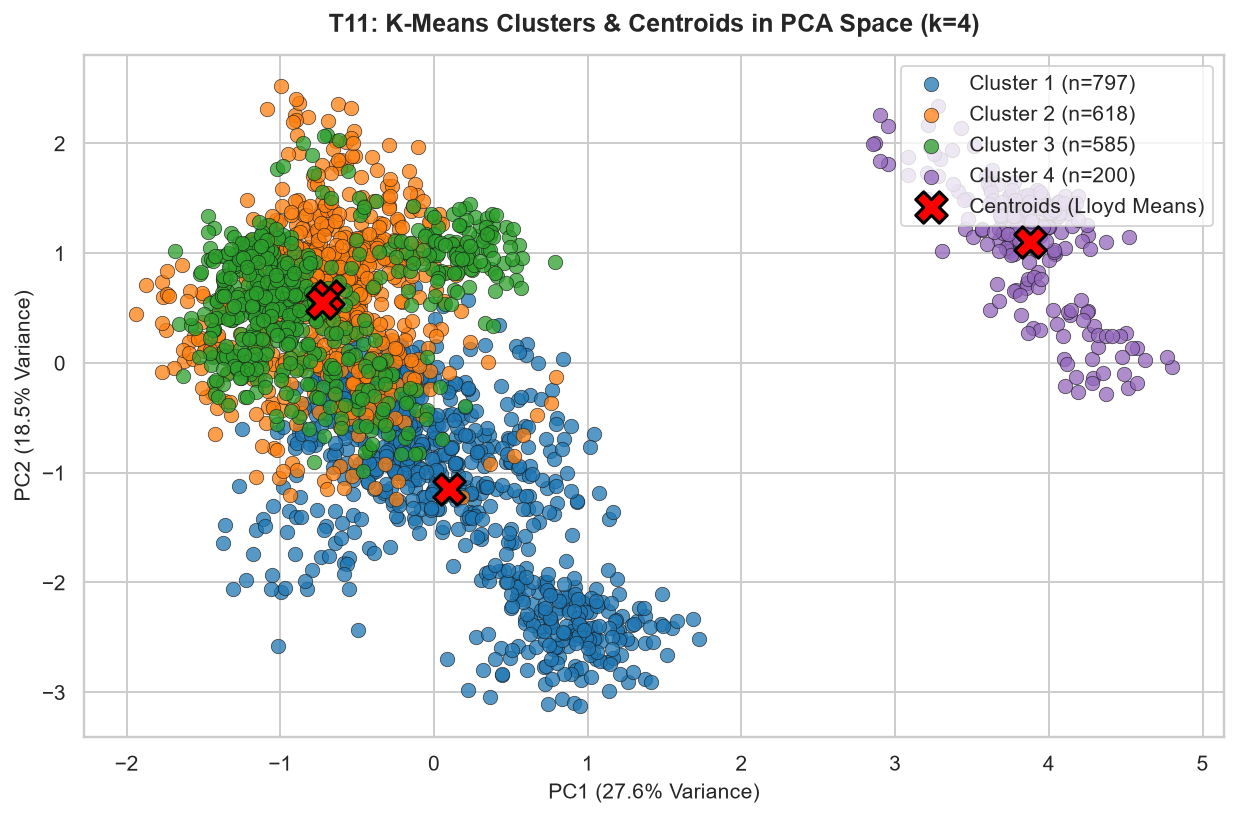

In [6]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
centers_pca = pca.transform(centroids_scaled)

plt.figure(figsize=(9, 6), dpi=140)
palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd']
for c in range(k_optimal):
    idx = (kmeans_labels == c)
    plt.scatter(
        X_pca[idx, 0], X_pca[idx, 1],
        label=f'Cluster {c+1} (n={idx.sum()})',
        color=palette[c], alpha=0.75, s=55, edgecolors='k', linewidth=0.4
    )

# Plot Centroids
plt.scatter(
    centers_pca[:, 0], centers_pca[:, 1],
    s=260, c='red', marker='X', edgecolor='black', linewidth=1.6,
    label='Centroids (Lloyd Means)', zorder=10
)

plt.title(f'T11: K-Means Clusters & Centroids in PCA Space (k={k_optimal})', fontsize=13, fontweight='bold', pad=12)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} Variance)', fontsize=11)
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} Variance)', fontsize=11)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

### Step 7: Predict Cluster for New Unseen Soil Test
We test the K-Means pipeline by assigning a new farmer's field sample to its closest agro-ecological cluster.

In [7]:
sample_input = np.array([[90, 42, 43, 20.8, 82.0, 6.5, 202.9]])  # High N, high humidity, high rainfall
sample_scaled = scaler.transform(sample_input)
predicted_cluster = kmeans.predict(sample_scaled)[0] + 1
print(f'Input Soil/Weather Test: {sample_input.tolist()[0]}')
print(f'Assigned Cluster: Cluster {predicted_cluster}')

Input Soil/Weather Test: [90.0, 42.0, 43.0, 20.8, 82.0, 6.5, 202.9]
Assigned Cluster: Cluster 2


### 🎓 Viva Voce Questions & Answers (Tutorial 11)

1. **Q: What is the purpose of K-Means++ initialization?**
   - **A:** Standard K-Means randomly picks initial centroids, which can lead to poor local optima and slow convergence. K-Means++ selects the first centroid uniformly at random, and then picks subsequent centroids with probability proportional to the squared distance to the nearest existing centroid. This spreads centroids apart initially, guaranteeing an $\mathcal{O}(\log k)$ competitive ratio.

2. **Q: What is Inertia (Within-Cluster Sum of Squares, WCSS)?**
   - **A:** Inertia measures internal cluster compactness. It is the sum of squared Euclidean distances from each data point to its assigned cluster centroid. Inertia naturally decreases as $k$ increases, reaching 0 when $k=n$.

3. **Q: What are the main limitations of K-Means?**
   - **A:** Assumes spherical clusters of similar size and density; highly sensitive to feature scaling and outliers; requires pre-specifying $k$.